# 01 · Análisis exploratorio (EDA) del dataset sintético SPI

**Proyecto 12 — Detector de anomalías en transferencias del SPI** · Luz Mereles · Sol Nuñez

Lee el CSV generado por `generar_datos.py` (`data/transacciones_spi.csv.gz`) y evalúa su **calidad** y su
**comportamiento**. Todos los gráficos se muestran aquí y además se guardan en `reports/eda/`.

| Sección | Contenido |
|---|---|
| 1 | Calidad e integridad: faltantes, duplicados, tipos y restricciones del esquema |
| 2 | Distribución de los montos y de las variables principales |
| 3 | Distribución de las clases (legítima / fraude) y de las tipologías |
| 4 | Comportamiento de las 14 features según la clase (**solo entrenamiento**) |
| 5 | Dispersión y proyección PCA para explorar el solapamiento entre clases |

**Cómo ejecutarlo en Google Colab:** subí la carpeta `detector-sip` completa a *Mi unidad* de Google Drive,
abrí este archivo desde Drive (*clic derecho → Abrir con → Google Colaboratory*) y elegí
*Entorno de ejecución → Ejecutar todas*. Colab pide permiso para acceder a Drive: es para leer el CSV y guardar los
gráficos en la misma carpeta. Los cambios del notebook se guardan solos en esa carpeta.

**En la PC (sin Colab):** instalá `requirements.txt` y abrí el notebook con Jupyter o VS Code desde la carpeta
`notebooks/`; la primera celda detecta que no está en Colab y usa la carpeta del proyecto.

In [1]:
# ---------- Preparación del entorno: Google Colab (con Drive) o local ----------
import os, sys, subprocess
from pathlib import Path

# Carpeta del proyecto en tu Google Drive. Si la guardaste en otro lugar, cambiá esta ruta.
CARPETA_EN_DRIVE = "/content/drive/MyDrive/detector-sip"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path(CARPETA_EN_DRIVE)
    # lo único que no trae Colab (optuna); el resto ya está instalado
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(RAIZ / "requirements-colab.txt")], check=True)
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CSV = RAIZ / "data" / "transacciones_spi.csv.gz"
assert CSV.exists(), f"No encuentro {CSV}. Revisá CARPETA_EN_DRIVE o ejecutá generar_datos.py"
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))   # para importar features.py (el mismo que usa la API)
print("Proyecto:", RAIZ)

Proyecto: /home/claude/detector-sip


In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Paleta validada: azul = legítima, naranja = fraude; colores de estado solo para decisiones
AZUL, NARANJA = "#2a78d6", "#eb6834"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
ESTADO = {"APROBAR": "#0ca30c", "REVISAR": "#fab219", "BLOQUEAR": "#d03b3b"}
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
CMAP_AZUL = matplotlib.colors.LinearSegmentedColormap.from_list("azul", ["#f4f8fd", "#86b6ef", "#256abf", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 170, "figure.dpi": 90,
    "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRILLA,
    "grid.linewidth": 0.6, "legend.frameon": False, "text.color": TINTA,
})
NOMBRE_TIPO = {"toma_de_cuenta": "Toma de cuenta", "rafaga_de_transferencias": "Ráfaga de transferencias",
               "cuenta_mula": "Cuenta mula", "camuflado": "Camuflado", "ninguno": "Legítima"}
ORDEN_TIPOS = ["toma_de_cuenta", "rafaga_de_transferencias", "cuenta_mula", "camuflado"]


def gs(v):
    return f"{v:,.0f}".replace(",", ".")


def guardar(fig, nombre):
    """Guarda la figura en la carpeta de salida y la muestra en el notebook."""
    fig.tight_layout()
    fig.savefig(SALIDA / nombre, bbox_inches="tight")
    plt.show()

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from features import (COLUMNAS_DATASET, FEATURES, INICIO_DATOS, FIN_DATOS, construir_features,
                      leer_dataset, particion)

MONTO_MINIMO, MONTO_MAXIMO = 1_000, 10_000_000
SALIDA = RAIZ / "reports" / "eda"
SALIDA.mkdir(parents=True, exist_ok=True)

## Carga del dataset

In [3]:
df = leer_dataset(CSV)
print(f"{len(df):,} transferencias x {df.shape[1]} columnas")
print("¿Columnas = esquema definido?", list(df.columns) == COLUMNAS_DATASET)
df.head()

1,689,911 transferencias x 18 columnas
¿Columnas = esquema definido? True


,transaction_id,timestamp,cuenta_emisor_id,banco_origen,banco_destino,cuenta_destino_id,ciudad,ciudad_habitual,dispositivo_id,monto_gs,n_tx_1h,n_tx_24h,monto_promedio_30d_gs,destinatario_nuevo,dispositivo_nuevo,antiguedad_cuenta_origen_dias,es_fraude,tipo_fraude
0,TX-00000001,2025-07-01 00:01:54,EMI-00526,Banco Continental,Interfisa Banco,CTA-10001526,Encarnación,Encarnación,DEV-1017068,690200,0,3,439646,False,False,1381,0,ninguno
1,TX-00000002,2025-07-01 00:01:58,EMI-03579,Banco Familiar,Interfisa Banco,CTA-10012825,Luque,Luque,DEV-1015094,19000,0,0,122694,True,False,1112,0,ninguno
2,TX-00000003,2025-07-01 00:03:30,EMI-03675,Visión Banco,Banco Atlas,CTA-10141052,Asunción,Asunción,DEV-1001401,260000,0,1,1937378,False,False,1328,0,ninguno
3,TX-00000004,2025-07-01 00:07:56,EMI-04150,Banco Continental,Banco Nacional de Fomento,CTA-10026765,Luque,Luque,DEV-1013346,286648,0,1,185283,False,False,937,0,ninguno
4,TX-00000005,2025-07-01 00:09:24,EMI-07620,Banco Continental,Banco Itaú,CTA-10046947,Capiatá,Capiatá,DEV-1001580,211658,0,1,321840,False,False,759,0,ninguno


## 1. Calidad e integridad

Se revisan faltantes, duplicados, tipos de datos y **restricciones del esquema**. La coherencia temporal se verifica
**recalculando** `n_tx_1h`, `n_tx_24h` y `monto_promedio_30d_gs` con ventanas móviles de pandas
(`rolling(..., closed="left")`, es decir, solo con transferencias **anteriores**) y comparándolas con las del CSV.
`destinatario_nuevo` solo puede ser verdadero en la primera transferencia de cada par emisor → destino.

`monto_promedio_30d_gs` vale **0** cuando el cliente no hizo transferencias en los 30 días anteriores: no es un
faltante, es "sin historial", y la feature `sin_historial` lo marca.

In [4]:
def calidad(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    tabla = pd.DataFrame({
        "tipo_de_dato": df.dtypes.astype(str),
        "faltantes": df.isna().sum(),
        "pct_faltantes": (df.isna().mean() * 100).round(3),
        "valores_distintos": df.nunique(),
    }).rename_axis("columna").reset_index()

    chequeos = []

    def chequear(nombre, violaciones, detalle=""):
        chequeos.append({"restriccion": nombre, "violaciones": int(violaciones),
                         "cumple": int(violaciones) == 0, "detalle": detalle})

    chequear("Columnas = esquema definido (18, en orden)", int(list(df.columns) != COLUMNAS_DATASET))
    chequear("transaction_id único", df["transaction_id"].duplicated().sum())
    chequear("Filas duplicadas completas", df.duplicated().sum())
    chequear("timestamp dentro de jul 2025 - jun 2026", (~df["timestamp"].between(INICIO_DATOS, FIN_DATOS, inclusive="left")).sum())
    chequear(f"monto_gs entre {gs(MONTO_MINIMO)} y {gs(MONTO_MAXIMO)} Gs.",
             (~df["monto_gs"].between(MONTO_MINIMO, MONTO_MAXIMO)).sum())
    chequear("Ninguna columna con valores faltantes", df.isna().any(axis=1).sum(),
             "monto_promedio_30d_gs = 0 cuando el cliente no tiene historial (sin_historial = 1)")
    chequear("n_tx_1h >= 0 y n_tx_24h >= n_tx_1h", ((df["n_tx_1h"] < 0) | (df["n_tx_24h"] < df["n_tx_1h"])).sum())
    chequear("monto_promedio_30d_gs >= 0", (df["monto_promedio_30d_gs"] < 0).sum())
    chequear("Promedio = 0 => sin transferencias en las últimas 24 h",
             ((df["monto_promedio_30d_gs"] == 0) & (df["n_tx_24h"] > 0)).sum())
    chequear("antiguedad_cuenta_origen_dias >= 0", (df["antiguedad_cuenta_origen_dias"] < 0).sum())
    chequear("es_fraude en {0, 1}", (~df["es_fraude"].isin([0, 1])).sum())
    chequear("tipo_fraude = 'ninguno' <=> es_fraude = 0", ((df["tipo_fraude"] == "ninguno") != (df["es_fraude"] == 0)).sum())

    # --- coherencia temporal: se recalcula con ventanas móviles y se compara
    s = df.sort_values(["cuenta_emisor_id", "timestamp", "transaction_id"]).reset_index(drop=True)
    empate = s.duplicated(["cuenta_emisor_id", "timestamp"], keep=False).to_numpy()  # mismo segundo
    g = s.groupby("cuenta_emisor_id", sort=False)
    roll = lambda v: g.rolling(v, on="timestamp", closed="left")["monto_gs"]  # noqa: E731  [t - v, t)
    n1h = roll("1h").count().fillna(0).to_numpy()   # ventana vacía -> 0 transferencias previas
    n24 = roll("24h").count().fillna(0).to_numpy()
    prom = roll("30D").mean().to_numpy()
    t = s["timestamp"]
    for nombre, calc, col, desde in [
        ("n_tx_1h = transferencias previas del emisor en [t-1h, t)", n1h, "n_tx_1h", INICIO_DATOS + pd.Timedelta(hours=1)),
        ("n_tx_24h = transferencias previas del emisor en [t-24h, t)", n24, "n_tx_24h", INICIO_DATOS + pd.Timedelta(days=1)),
    ]:
        m = (t >= desde).to_numpy() & ~empate
        chequear(nombre, (calc[m] != s[col].to_numpy()[m]).sum(),
                 f"recalculado con pandas.rolling en {m.sum():,} filas (desde {desde:%d/%m %H:%M}; "
                 "antes depende del historial de junio 2025)")
    m = (t >= INICIO_DATOS + pd.Timedelta(days=30)).to_numpy() & ~empate
    dif = np.abs(np.nan_to_num(prom[m], nan=0) - s["monto_promedio_30d_gs"].to_numpy()[m])  # sin historial -> 0
    chequear("monto_promedio_30d_gs = promedio de montos previos en 30 días", (dif > 0.5).sum(),
             f"recalculado en {m.sum():,} filas (desde 31/07)")

    # destinatario_nuevo: solo puede ser True en la PRIMERA transferencia del par emisor-destino
    primera = ~s.duplicated(["cuenta_emisor_id", "cuenta_destino_id"], keep="first")
    chequear("destinatario_nuevo = True solo en la primera transferencia emisor->destino",
             (s["destinatario_nuevo"] & ~primera).sum())
    explicadas = int((primera & ~s["destinatario_nuevo"]).sum())
    chequear("Primera aparición del par en el dataset marcada como no nueva => ya pagó en junio 2025",
             0, f"{explicadas:,} pares con historial previo en junio 2025 (fuera del CSV); no es un error")
    # dispositivo_nuevo: True solo si el dispositivo apareció por primera vez hace <= 24 h
    primera_disp = s.groupby(["cuenta_emisor_id", "dispositivo_id"])["timestamp"].transform("min")
    m = (primera_disp >= INICIO_DATOS + pd.Timedelta(days=1)).to_numpy()
    chequear("dispositivo_nuevo = True solo si se vio por primera vez hace <= 24 h",
             (s["dispositivo_nuevo"].to_numpy() & ((t - primera_disp) > pd.Timedelta(hours=24)).to_numpy() & m).sum())
    return tabla, pd.DataFrame(chequeos)


tabla_calidad, chequeos = calidad(df)
tabla_calidad.to_csv(SALIDA / "calidad_columnas.csv", index=False)
chequeos.to_csv(SALIDA / "restricciones.csv", index=False)
display(tabla_calidad)
display(chequeos)
print("¿Se cumplen todas las restricciones?", bool(chequeos["cumple"].all()))

,columna,tipo_de_dato,faltantes,pct_faltantes,valores_distintos
0,transaction_id,str,0,0.0,1689911
1,timestamp,datetime64[us],0,0.0,1620947
2,cuenta_emisor_id,str,0,0.0,8040
3,banco_origen,str,0,0.0,12
4,banco_destino,str,0,0.0,12
5,cuenta_destino_id,str,0,0.0,169771
6,ciudad,str,0,0.0,18
7,ciudad_habitual,str,0,0.0,18
8,dispositivo_id,str,0,0.0,19181
9,monto_gs,int64,0,0.0,345872


,restriccion,violaciones,cumple,detalle
0,"Columnas = esquema definido (18, en orden)",0,True,
1,transaction_id único,0,True,
2,Filas duplicadas completas,0,True,
3,timestamp dentro de jul 2025 - jun 2026,0,True,
4,monto_gs entre 1.000 y 10.000.000 Gs.,0,True,
5,Ninguna columna con valores faltantes,0,True,monto_promedio_30d_gs = 0 cuando el cliente no...
6,n_tx_1h >= 0 y n_tx_24h >= n_tx_1h,0,True,
7,monto_promedio_30d_gs >= 0,0,True,
8,Promedio = 0 => sin transferencias en las últi...,0,True,
9,antiguedad_cuenta_origen_dias >= 0,0,True,


¿Se cumplen todas las restricciones? True


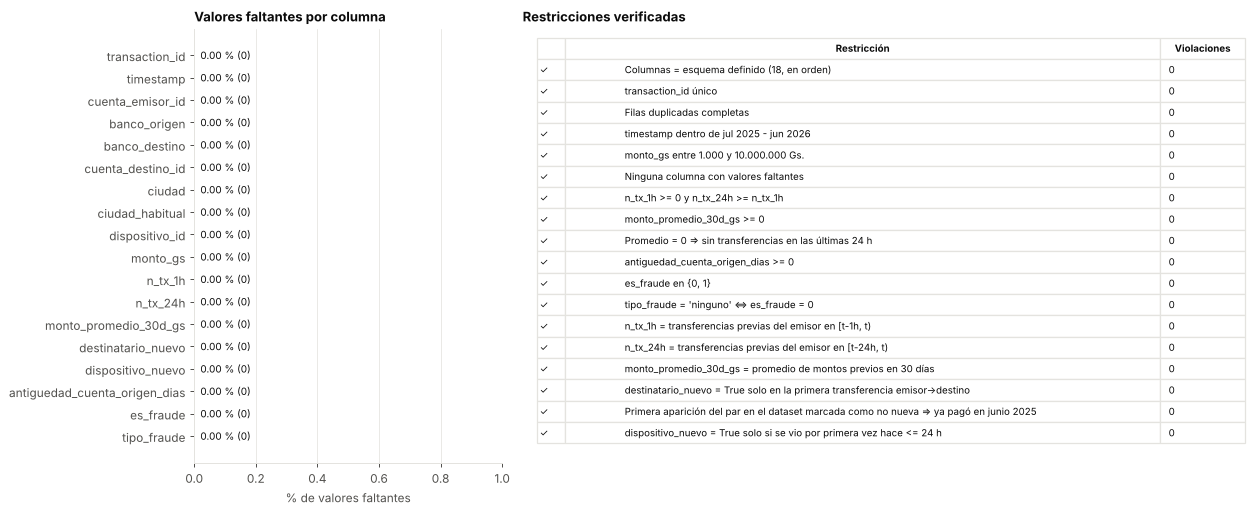

In [5]:
def figura_calidad(tabla: pd.DataFrame, chequeos: pd.DataFrame):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1, 2.3]})
    a1.barh(tabla["columna"][::-1], tabla["pct_faltantes"][::-1], color=AZUL, height=0.6)
    for i, (v, n) in enumerate(zip(tabla["pct_faltantes"][::-1], tabla["faltantes"][::-1])):
        a1.text(v + 0.02, i, f"{v:.2f} % ({gs(n)})", va="center", fontsize=8)
    a1.set(xlabel="% de valores faltantes", title="Valores faltantes por columna", xlim=(0, max(1, tabla["pct_faltantes"].max() * 1.6)))
    a1.grid(axis="y", visible=False)
    a2.axis("off")
    a2.set_title("Restricciones verificadas", loc="left")
    filas = [["✓" if c else "✗", r, gs(v)] for c, r, v in
             zip(chequeos["cumple"], chequeos["restriccion"], chequeos["violaciones"])]
    tb = a2.table(cellText=filas, colLabels=["", "Restricción", "Violaciones"], loc="upper left",
                  colWidths=[0.04, 0.84, 0.12], cellLoc="left")
    tb.auto_set_font_size(False)
    tb.set_fontsize(7.8)
    tb.scale(1, 1.32)
    for (r, c), cel in tb.get_celld().items():
        cel.set_edgecolor(GRILLA)
        if r == 0:
            cel.set_text_props(weight="bold")
    guardar(fig, "01_calidad_integridad.png")


figura_calidad(tabla_calidad, chequeos)

## 2. Distribución de los montos y de las variables principales

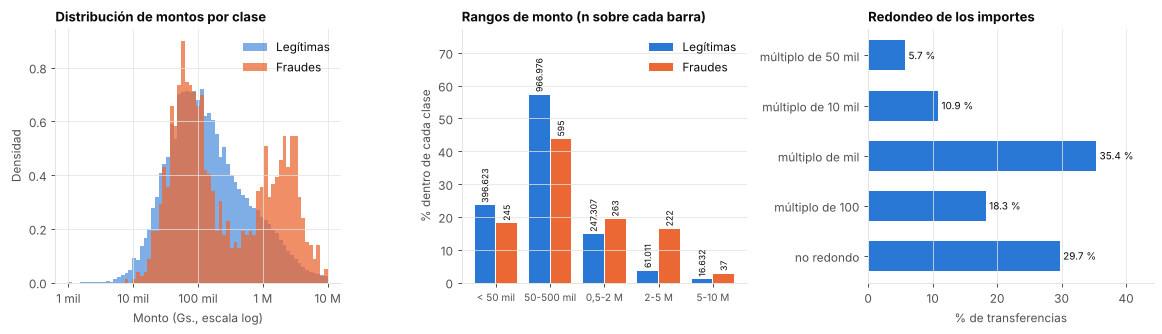

In [6]:
def figura_montos(df: pd.DataFrame):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    bins = np.linspace(3, 7, 70)
    for clase, color, nombre in [(0, AZUL, "Legítimas"), (1, NARANJA, "Fraudes")]:
        v = np.log10(df.loc[df["es_fraude"] == clase, "monto_gs"])
        ax[0].hist(v, bins=bins, density=True, color=color, alpha=0.6 if clase == 0 else 0.75, label=nombre)
    ax[0].set_xticks([3, 4, 5, 6, 7], ["1 mil", "10 mil", "100 mil", "1 M", "10 M"])
    ax[0].set(xlabel="Monto (Gs., escala log)", ylabel="Densidad", title="Distribución de montos por clase")
    ax[0].legend()

    rangos = [0, 50_000, 500_000, 2_000_000, 5_000_000, MONTO_MAXIMO + 1]
    etiquetas = ["< 50 mil", "50-500 mil", "0,5-2 M", "2-5 M", "5-10 M"]
    r = pd.cut(df["monto_gs"], rangos, right=False, labels=etiquetas)
    ct = pd.crosstab(r, df["es_fraude"])
    pct = ct.div(ct.sum(axis=0), axis=1) * 100
    x = np.arange(len(etiquetas))
    ax[1].bar(x - 0.2, pct[0], 0.38, color=AZUL, label="Legítimas")
    ax[1].bar(x + 0.2, pct[1], 0.38, color=NARANJA, label="Fraudes")
    for i in range(len(x)):
        ax[1].text(x[i] - 0.2, pct[0].iloc[i] + 0.8, gs(ct[0].iloc[i]), ha="center", fontsize=7, rotation=90, va="bottom")
        ax[1].text(x[i] + 0.2, pct[1].iloc[i] + 0.8, gs(ct[1].iloc[i]), ha="center", fontsize=7, rotation=90, va="bottom")
    ax[1].set_xticks(x, etiquetas, fontsize=8)
    ax[1].set(ylabel="% dentro de cada clase", title="Rangos de monto (n sobre cada barra)", ylim=(0, pct.values.max() * 1.35))
    ax[1].legend()
    ax[1].grid(axis="x", visible=False)

    m = df["monto_gs"]
    gran = np.select([m % 50_000 == 0, m % 10_000 == 0, m % 1_000 == 0, m % 100 == 0],
                     ["múltiplo de 50 mil", "múltiplo de 10 mil", "múltiplo de mil", "múltiplo de 100"], "no redondo")
    orden = ["múltiplo de 50 mil", "múltiplo de 10 mil", "múltiplo de mil", "múltiplo de 100", "no redondo"]
    vc = pd.Series(gran).value_counts(normalize=True).reindex(orden) * 100
    ax[2].barh(orden[::-1], vc[::-1], color=AZUL, height=0.6)
    for i, v in enumerate(vc[::-1]):
        ax[2].text(v + 0.5, i, f"{v:.1f} %", va="center", fontsize=8)
    ax[2].set(xlabel="% de transferencias", title="Redondeo de los importes", xlim=(0, vc.max() * 1.25))
    ax[2].grid(axis="y", visible=False)
    guardar(fig, "02_distribucion_montos.png")


figura_montos(df)

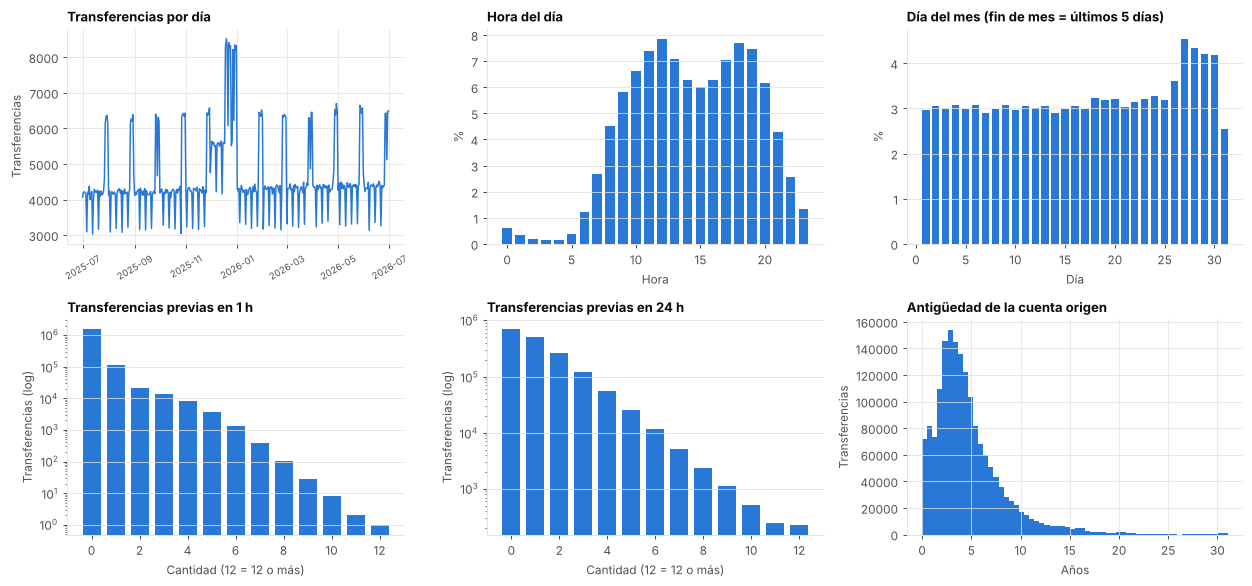

In [7]:
def figura_variables(df: pd.DataFrame):
    fig, ax = plt.subplots(2, 3, figsize=(14, 6.6))
    ax = ax.ravel()
    por_dia = df.set_index("timestamp").resample("D")["transaction_id"].count()
    ax[0].plot(por_dia.index, por_dia.values, color=AZUL, lw=1.2)
    ax[0].set(title="Transferencias por día", ylabel="Transferencias")
    ax[0].tick_params(axis="x", labelsize=7.5, rotation=30)

    h = df["timestamp"].dt.hour.value_counts(normalize=True).sort_index() * 100
    ax[1].bar(h.index, h.values, color=AZUL, width=0.75)
    ax[1].set(title="Hora del día", xlabel="Hora", ylabel="%")
    ax[1].grid(axis="x", visible=False)

    d = df["timestamp"].dt.day.value_counts(normalize=True).sort_index() * 100
    ax[2].bar(d.index, d.values, color=AZUL, width=0.75)
    ax[2].set(title="Día del mes (fin de mes = últimos 5 días)", xlabel="Día", ylabel="%")
    ax[2].grid(axis="x", visible=False)

    for i, col, titulo in [(3, "n_tx_1h", "Transferencias previas en 1 h"), (4, "n_tx_24h", "Transferencias previas en 24 h")]:
        vc = df[col].clip(upper=12).value_counts().sort_index()
        ax[i].bar(vc.index, vc.values, color=AZUL, width=0.75)
        ax[i].set_yscale("log")
        ax[i].set(title=titulo, xlabel="Cantidad (12 = 12 o más)", ylabel="Transferencias (log)")
        ax[i].grid(axis="x", visible=False)

    ax[5].hist(df["antiguedad_cuenta_origen_dias"] / 365, bins=60, color=AZUL)
    ax[5].set(title="Antigüedad de la cuenta origen", xlabel="Años", ylabel="Transferencias")
    guardar(fig, "03_variables_principales.png")


figura_variables(df)

## 3. Distribución de las clases y de las tipologías

Los porcentajes de las tipologías se definieron como **casos** (toma de cuenta 45 %, ráfaga 25 %, cuenta mula 20 %,
camuflado 10 %). Un caso puede tener varias transferencias (una ráfaga tiene 3 a 7, una cuenta mula 2 a 5, un camuflado
1 o 2), por eso el gráfico de **transferencias** fraudulentas muestra otra proporción: en transferencias la ráfaga
queda primera. El camuflado es la tipología más chica tanto en casos como en transferencias.

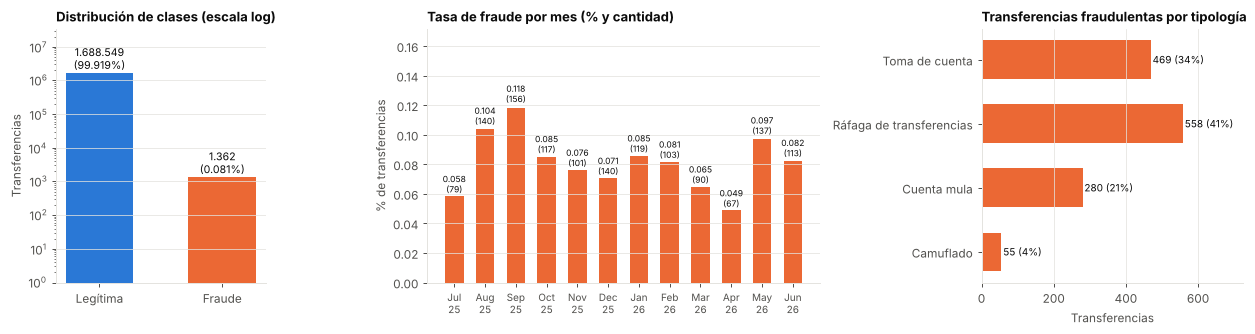

In [8]:
def figura_clases(df: pd.DataFrame):
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [0.8, 1.5, 1]})
    vc = df["es_fraude"].value_counts().sort_index()
    ax[0].bar(["Legítima", "Fraude"], vc.values, color=[AZUL, NARANJA], width=0.55)
    ax[0].set_yscale("log")
    for i, v in enumerate(vc.values):
        ax[0].text(i, v * 1.3, f"{gs(v)}\n({v / vc.sum():.3%})", ha="center", fontsize=8.5)
    ax[0].set(title="Distribución de clases (escala log)", ylabel="Transferencias", ylim=(1, vc.max() * 20))
    ax[0].grid(axis="x", visible=False)

    mes = df.groupby(df["timestamp"].dt.to_period("M"))["es_fraude"].agg(["mean", "sum"])
    x = np.arange(len(mes))
    ax[1].bar(x, mes["mean"] * 100, color=NARANJA, width=0.6)
    for i, (r, s) in enumerate(zip(mes["mean"], mes["sum"])):
        ax[1].text(i, r * 100 * 1.02, f"{r * 100:.3f}\n({s})", ha="center", fontsize=6.8, va="bottom")
    ax[1].set_xticks(x, [p.strftime("%b\n%y") for p in mes.index], fontsize=8)
    ax[1].set(title="Tasa de fraude por mes (% y cantidad)", ylabel="% de transferencias", ylim=(0, mes["mean"].max() * 145))
    ax[1].grid(axis="x", visible=False)

    t = df.loc[df["es_fraude"] == 1, "tipo_fraude"].value_counts().reindex(ORDEN_TIPOS)
    ax[2].barh([NOMBRE_TIPO[k] for k in ORDEN_TIPOS][::-1], t.values[::-1], color=NARANJA, height=0.6)
    for i, v in enumerate(t.values[::-1]):
        ax[2].text(v + 5, i, f"{v} ({v / t.sum():.0%})", va="center", fontsize=8)
    ax[2].set(title="Transferencias fraudulentas por tipología", xlabel="Transferencias", xlim=(0, t.max() * 1.3))
    ax[2].grid(axis="y", visible=False)
    guardar(fig, "04_distribucion_clases.png")


figura_clases(df)

## 4. Comportamiento de las features según la clase

Solo con el **conjunto de entrenamiento (jul 2025 – feb 2026)**: validación y prueba no se miran antes de modelar.
El mapa por tipología sirve para analizar los escenarios; `tipo_fraude` **nunca** se usa para entrenar, y las
relaciones que se vean aquí no agregan features nuevas.

Entrenamiento: 1,136,689 transferencias, 955 fraudes


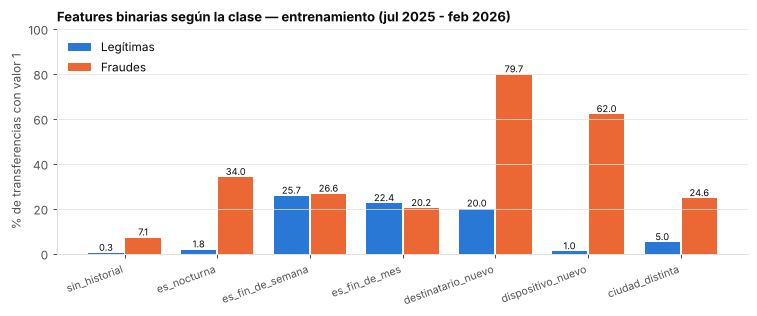

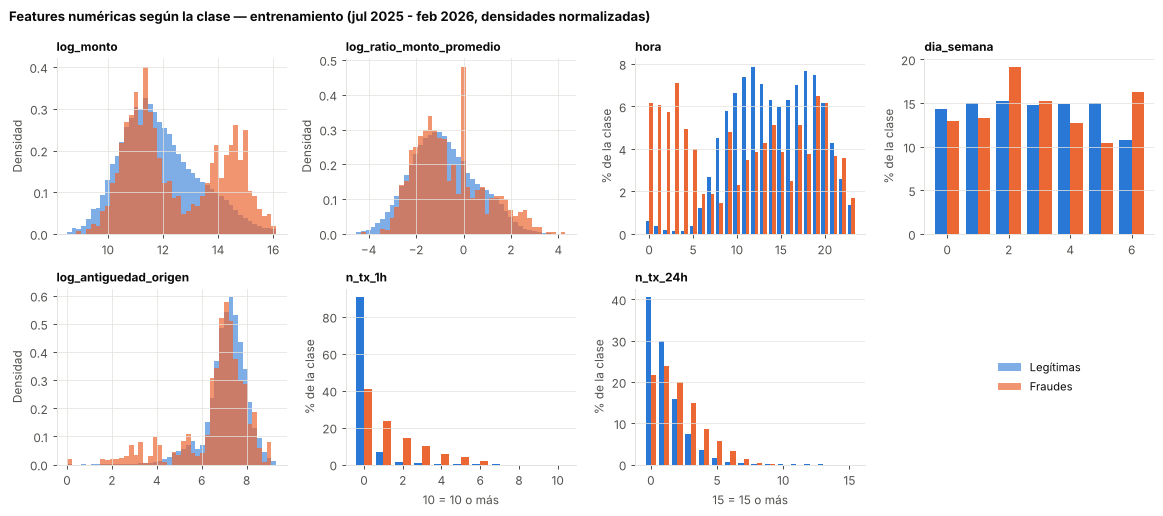

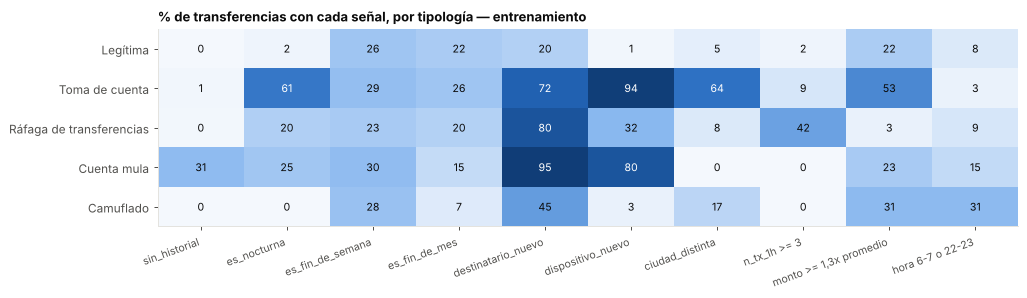

,legitima_mean,legitima_median,fraude_mean,fraude_median
log_monto,11.8772,11.6953,12.5002,11.9223
log_ratio_monto_promedio,-0.8198,-0.9270,-0.5922,-0.8787
sin_historial,0.0029,0.0000,0.0712,0.0000
hora,14.2973,14.0000,10.8743,12.0000
es_nocturna,0.0180,0.0000,0.3403,0.0000
dia_semana,2.8888,3.0000,2.9738,3.0000
es_fin_de_semana,0.2570,0.0000,0.2660,0.0000
es_fin_de_mes,0.2240,0.0000,0.2021,0.0000
log_antiguedad_origen,7.1005,7.2182,6.6579,7.0510
n_tx_1h,0.1512,0.0000,1.3455,1.0000


In [9]:
es_entrenamiento = (particion(df["timestamp"]) == "entrenamiento").to_numpy()
X_tr = construir_features(df[es_entrenamiento])
y_tr = df.loc[es_entrenamiento, "es_fraude"].to_numpy()
tipo_tr = df.loc[es_entrenamiento, "tipo_fraude"]
print(f"Entrenamiento: {len(X_tr):,} transferencias, {y_tr.sum():,} fraudes")

BINARIAS = ["sin_historial", "es_nocturna", "es_fin_de_semana", "es_fin_de_mes",
            "destinatario_nuevo", "dispositivo_nuevo", "ciudad_distinta"]
CONTINUAS = ["log_monto", "log_ratio_monto_promedio", "hora", "dia_semana",
             "log_antiguedad_origen", "n_tx_1h", "n_tx_24h"]


def features_por_clase(X: pd.DataFrame, y: np.ndarray, tipo: pd.Series) -> pd.DataFrame:
    resumen = X.groupby(y).agg(["mean", "median"]).T.unstack()
    resumen.columns = [f"{'legitima' if c == 0 else 'fraude'}_{e}" for c, e in resumen.columns]
    resumen = resumen.reindex(FEATURES).round(4)

    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    tasas = X[BINARIAS].groupby(y).mean().T * 100
    x = np.arange(len(BINARIAS))
    ax.bar(x - 0.2, tasas[0], 0.38, color=AZUL, label="Legítimas")
    ax.bar(x + 0.2, tasas[1], 0.38, color=NARANJA, label="Fraudes")
    for i in range(len(x)):
        ax.text(x[i] - 0.2, tasas[0].iloc[i] + 1, f"{tasas[0].iloc[i]:.1f}", ha="center", fontsize=7.5)
        ax.text(x[i] + 0.2, tasas[1].iloc[i] + 1, f"{tasas[1].iloc[i]:.1f}", ha="center", fontsize=7.5)
    ax.set_xticks(x, BINARIAS, rotation=20, ha="right", fontsize=8.5)
    ax.set(ylabel="% de transferencias con valor 1", title="Features binarias según la clase — entrenamiento (jul 2025 - feb 2026)",
           ylim=(0, 100))
    ax.legend(loc="upper left")
    ax.grid(axis="x", visible=False)
    guardar(fig, "05_features_binarias_por_clase.png")

    fig, axs = plt.subplots(2, 4, figsize=(13, 5.8))
    axs = axs.ravel()
    for a, col in zip(axs, CONTINUAS):
        v0, v1 = X.loc[y == 0, col], X.loc[y == 1, col]
        if col in ("hora", "dia_semana", "n_tx_1h", "n_tx_24h"):
            tope = {"hora": 23, "dia_semana": 6, "n_tx_1h": 10, "n_tx_24h": 15}[col]
            k = np.arange(tope + 1)
            p0 = v0.clip(upper=tope).value_counts(normalize=True).reindex(k, fill_value=0) * 100
            p1 = v1.clip(upper=tope).value_counts(normalize=True).reindex(k, fill_value=0) * 100
            a.bar(k - 0.2, p0, 0.4, color=AZUL, label="Legítimas")
            a.bar(k + 0.2, p1, 0.4, color=NARANJA, label="Fraudes")
            a.set_ylabel("% de la clase")
            a.grid(axis="x", visible=False)
            if col in ("n_tx_1h", "n_tx_24h"):
                a.set_xlabel(f"{tope} = {tope} o más")
        else:
            bins = np.linspace(min(v0.quantile(0.001), v1.min()), max(v0.quantile(0.999), v1.max()), 45)
            a.hist(v0, bins=bins, density=True, color=AZUL, alpha=0.6, label="Legítimas")
            a.hist(v1, bins=bins, density=True, color=NARANJA, alpha=0.7, label="Fraudes")
            a.set_ylabel("Densidad")
        a.set_title(col, fontsize=9.5)
    axs[-1].axis("off")
    axs[-1].legend(*axs[0].get_legend_handles_labels(), loc="center", fontsize=9)
    fig.suptitle("Features numéricas según la clase — entrenamiento (jul 2025 - feb 2026, densidades normalizadas)",
                 x=0.01, ha="left", fontweight="bold", fontsize=10.5)
    guardar(fig, "06_features_numericas_por_clase.png")

    # tasa de cada feature binaria por tipología (para analizar los escenarios, no se usa para entrenar)
    tab = X[BINARIAS].groupby(tipo).mean().reindex(["ninguno"] + ORDEN_TIPOS) * 100
    tab["n_tx_1h >= 3"] = (X["n_tx_1h"] >= 3).groupby(tipo).mean().reindex(tab.index) * 100
    # rarezas leves del camuflado: también deben ser frecuentes en las legítimas
    tab["monto >= 1,3x promedio"] = (X["log_ratio_monto_promedio"] >= np.log(1.3)).groupby(tipo).mean().reindex(tab.index) * 100
    tab["hora 6-7 o 22-23"] = X["hora"].isin([6, 7, 22, 23]).groupby(tipo).mean().reindex(tab.index) * 100
    fig, ax = plt.subplots(figsize=(11.5, 3.4))
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list("azul", ["#f4f8fd", "#86b6ef", "#256abf", "#0d366b"])
    ax.imshow(tab.to_numpy(), cmap=cmap, vmin=0, vmax=100, aspect="auto")
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.iat[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if v > 55 else TINTA)
    ax.set_xticks(range(tab.shape[1]), tab.columns, rotation=20, ha="right", fontsize=8.5)
    ax.set_yticks(range(tab.shape[0]), [NOMBRE_TIPO[k] for k in tab.index])
    ax.grid(False)
    ax.set_title("% de transferencias con cada señal, por tipología — entrenamiento")
    guardar(fig, "07_senales_por_tipologia.png")
    return resumen


resumen = features_por_clase(X_tr, y_tr, tipo_tr)
resumen.to_csv(SALIDA / "features_por_clase_entrenamiento.csv")
resumen

## 5. Dispersión y proyección bidimensional

**Método:** PCA (análisis de componentes principales) sobre las 14 features estandarizadas; el escalado y la PCA se
ajustan con el conjunto de entrenamiento. Es una proyección **lineal** que conserva solo una parte de la varianza:
sirve para *explorar* el solapamiento, **no** es evidencia de que las clases sean (o no) separables en el espacio
original de 14 dimensiones.

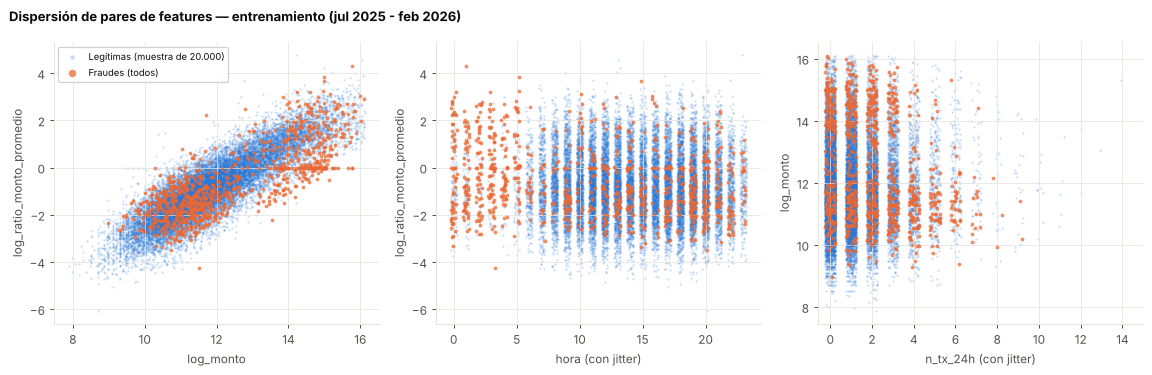

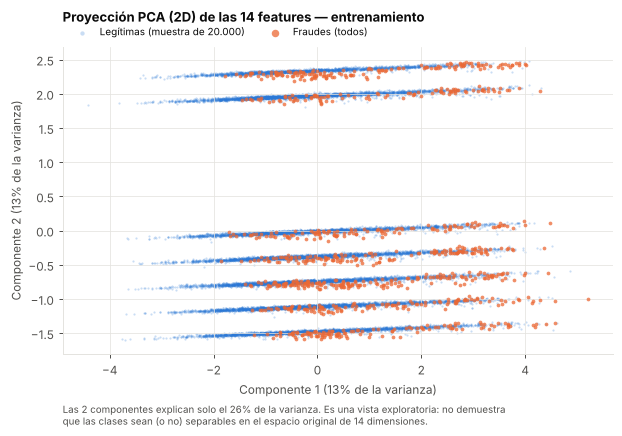

In [10]:
def figura_dispersion(X: pd.DataFrame, y: np.ndarray, seed: int = 7):
    rng = np.random.default_rng(seed)
    leg = np.where(y == 0)[0]
    idx = np.concatenate([rng.choice(leg, 20_000, replace=False), np.where(y == 1)[0]])
    Xs, ys = X.iloc[idx], y[idx]
    jit = lambda n, a=0.25: rng.uniform(-a, a, n)  # noqa: E731  (dispersión visual para valores enteros)
    pares = [("log_monto", "log_ratio_monto_promedio", False),
             ("hora", "log_ratio_monto_promedio", True),
             ("n_tx_24h", "log_monto", True)]
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
    for a, (cx, cy, j) in zip(axs, pares):
        for clase, color, nombre, s, z in [(0, AZUL, "Legítimas (muestra de 20.000)", 3, 1), (1, NARANJA, "Fraudes (todos)", 9, 2)]:
            m = ys == clase
            xv = Xs.loc[m, cx].to_numpy(dtype=float)
            if j:
                xv = xv + jit(m.sum())
            a.scatter(xv, Xs.loc[m, cy], s=s, color=color, alpha=0.25 if clase == 0 else 0.75,
                      linewidths=0, label=nombre, zorder=z)
        a.set(xlabel=cx + (" (con jitter)" if j else ""), ylabel=cy)
        if cx == "n_tx_24h":
            a.set_xlim(-0.6, 15)
    axs[0].legend(loc="upper left", fontsize=7.5, markerscale=2, framealpha=0.9, frameon=True)
    fig.suptitle("Dispersión de pares de features — entrenamiento (jul 2025 - feb 2026)", x=0.01, ha="left",
                 fontweight="bold", fontsize=10.5)
    guardar(fig, "08_dispersion_pares.png")

    # PCA: proyección LINEAL de las 14 features estandarizadas (ajustada solo con entrenamiento)
    esc = StandardScaler().fit(X)
    pca = PCA(n_components=2, random_state=seed).fit(esc.transform(X))
    Z = pca.transform(esc.transform(Xs))
    fig, ax = plt.subplots(figsize=(7, 5))
    for clase, color, nombre, s, z in [(0, AZUL, "Legítimas (muestra de 20.000)", 3, 1), (1, NARANJA, "Fraudes (todos)", 9, 2)]:
        m = ys == clase
        ax.scatter(Z[m, 0], Z[m, 1], s=s, color=color, alpha=0.25 if clase == 0 else 0.75, linewidths=0,
                   label=nombre, zorder=z)
    ev = pca.explained_variance_ratio_
    ax.set(xlabel=f"Componente 1 ({ev[0]:.0%} de la varianza)", ylabel=f"Componente 2 ({ev[1]:.0%} de la varianza)",
           title="Proyección PCA (2D) de las 14 features — entrenamiento")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8, markerscale=2)
    ax.set_title(ax.get_title(loc="left"), loc="left", pad=20)
    ax.text(0.0, -0.16, f"Las 2 componentes explican solo el {ev.sum():.0%} de la varianza. Es una vista "
            "exploratoria: no demuestra\nque las clases sean (o no) separables en el espacio original de 14 dimensiones.",
            transform=ax.transAxes, fontsize=7.8, color=TINTA_2, va="top")
    guardar(fig, "09_proyeccion_pca.png")
    return ev


varianza_pca = figura_dispersion(X_tr, y_tr)

## 6. Resumen exportado (`reports/eda/EDA.md`)

In [11]:
fr = df[df["es_fraude"] == 1]
tipos = fr["tipo_fraude"].value_counts().reindex(ORDEN_TIPOS)
m = df["monto_gs"]
part = particion(df["timestamp"])
por_particion = df.groupby(part)["es_fraude"].agg(transferencias="count", fraudes="sum").reindex(
    ["entrenamiento", "validacion", "prueba"])
lineas = [
    "# EDA del dataset sintético SPI (generado por notebooks/01_eda.ipynb)", "",
    f"- Transferencias: **{gs(len(df))}** · fraudes: **{gs(len(fr))}** ({df['es_fraude'].mean():.4%})",
    f"- Período: {df['timestamp'].min():%d/%m/%Y %H:%M} – {df['timestamp'].max():%d/%m/%Y %H:%M}",
    f"- Emisores: {gs(df['cuenta_emisor_id'].nunique())} · cuentas destino: {gs(df['cuenta_destino_id'].nunique())} · "
    f"bancos: {df['banco_origen'].nunique()} · ciudades: {df['ciudad'].nunique()}",
    f"- Monto: mínimo Gs. {gs(m.min())}, mediana Gs. {gs(m.median())}, máximo Gs. {gs(m.max())}",
    f"- Importes que no son múltiplo de 1.000: {(m % 1000 != 0).mean():.1%} · múltiplos de 10.000: {(m % 10000 == 0).mean():.1%}",
    f"- Transferencias legítimas de Gs. 5 millones o más: {gs(((df['es_fraude'] == 0) & (m >= 5_000_000)).sum())} · "
    f"fraudes menores a Gs. 100.000: {gs(((df['es_fraude'] == 1) & (m < 100_000)).sum())}",
    f"- Transferencias sin historial (monto_promedio_30d_gs = 0): {gs((df['monto_promedio_30d_gs'] == 0).sum())}",
    f"- Proyección PCA: las 2 primeras componentes explican {varianza_pca.sum():.1%} de la varianza", "",
    "## Partición temporal", "", por_particion.to_markdown(), "",
    "## Transferencias fraudulentas por tipología", "",
    pd.DataFrame({"transferencias": tipos, "porcentaje": (tipos / tipos.sum() * 100).round(1),
                  "monto_mediano_gs": fr.groupby("tipo_fraude")["monto_gs"].median().reindex(ORDEN_TIPOS).map(gs),
                  "monto_minimo_gs": fr.groupby("tipo_fraude")["monto_gs"].min().reindex(ORDEN_TIPOS).map(gs),
                  "monto_maximo_gs": fr.groupby("tipo_fraude")["monto_gs"].max().reindex(ORDEN_TIPOS).map(gs)}
                 ).to_markdown(disable_numparse=True), "",
    "## Restricciones verificadas", "",
    chequeos.assign(cumple=chequeos["cumple"].map({True: "✓", False: "✗"})).to_markdown(index=False), "",
    "## Calidad por columna", "", tabla_calidad.to_markdown(index=False), "",
    "## Features según la clase (entrenamiento, jul 2025 - feb 2026)", "", resumen.to_markdown(), "",
]
(SALIDA / "EDA.md").write_text("\n".join(lineas), encoding="utf-8")
display(Markdown("\n".join(lineas[:12])))
print("Gráficos y tablas guardados en", SALIDA)

# EDA del dataset sintético SPI (generado por notebooks/01_eda.ipynb)

- Transferencias: **1.689.911** · fraudes: **1.362** (0.0806%)
- Período: 01/07/2025 00:01 – 30/06/2026 23:59
- Emisores: 8.040 · cuentas destino: 169.771 · bancos: 12 · ciudades: 18
- Monto: mínimo Gs. 1.000, mediana Gs. 118.143, máximo Gs. 10.000.000
- Importes que no son múltiplo de 1.000: 48.0% · múltiplos de 10.000: 16.6%
- Transferencias legítimas de Gs. 5 millones o más: 16.632 · fraudes menores a Gs. 100.000: 555
- Transferencias sin historial (monto_promedio_30d_gs = 0): 5.143
- Proyección PCA: las 2 primeras componentes explican 26.1% de la varianza

## Partición temporal

Gráficos y tablas guardados en /home/claude/detector-sip/reports/eda


## 7. Conclusiones

- El dataset cumple todas las restricciones del esquema y no tiene valores faltantes.
- Las variables de contexto son coherentes con la secuencia temporal: se recalcularon sin usar datos futuros y coinciden.
- El fraude es muy minoritario (< 0,1 %): la *accuracy* no sirve como métrica; se usarán average precision, F1,
  precisión y recall (notebook `02_entrenamiento.ipynb`).
- Ninguna señal separa las clases por sí sola: el destinatario nuevo, el dispositivo nuevo, el horario nocturno o las
  ráfagas aparecen también en transferencias legítimas, así que el modelo tiene que **combinar** señales.
- El **camuflado** no tiene las señales fuertes (dispositivo nuevo, madrugada, ráfaga, cuenta reciente). Sus rarezas
  leves (destinatario nuevo, monto algo mayor a su promedio, horario de borde, otra ciudad) son más frecuentes que en
  las legítimas, pero también aparecen en miles de transferencias legítimas: es la tipología más difícil de detectar.